In [1]:
import pandas as pd
import numpy as np

In [2]:
logs = pd.read_csv("ALL_logs_kurssidata.csv", sep=";")
print(logs.columns)
print(logs.head(6))
print(logs.dtypes)

Index(['Aika', 'Tapahtuman konteksti', 'Komponentti', 'Tapahtuman nimi',
       'Kuvaus', 'Alkuperä'],
      dtype='str')
                   Aika                  Tapahtuman konteksti  Komponentti  \
0   3.02.2026, 11.48.49      Kurssi: Esi- ja alkuopetus kl-25   Lokitiedot   
1   3.02.2026, 11.47.44      Kurssi: Esi- ja alkuopetus kl-25  Järjestelmä   
2   3.02.2026, 00.48.00         Tentti: Tentti 2.5.-16.5.2025       Tentti   
3   3.02.2026, 00.47.46  Tentti: Uusintatentti 6.6.-13.6.2025       Tentti   
4   3.02.2026, 00.39.38      Kurssi: Esi- ja alkuopetus kl-25  Järjestelmä   
5  30.01.2026, 18.27.07      Kurssi: Esi- ja alkuopetus kl-25   Lokitiedot   

         Tapahtuman nimi                                             Kuvaus  \
0  Lokiraportti katsottu  The user with id '179434' viewed the log repor...   
1           Kurssi nähty  The user with id '179434' viewed the course wi...   
2  Kurssin moduuli nähty  The user with id '268877' viewed the 'quiz' ac...   
3  Kurssin modu

Poistettavat idt:

179434, 
179631,
44240,
14552,
14294,
4688,
54402,
39644,
87979,
15115,
31281,
173796,
44240,
2067,
204691,
48118,
Id '-1’ 

In [3]:
l = ["179434", "179631", "44240", "14552", "14294", "4688", "54402", "39644", "87979", "15115", "31281", "173796",
      "44240", "2067", "204691", "48118", "-1" ]
logs1 = logs.copy()

print(logs1.shape)
print(logs1.shape)
for i in l:
    colname = "Incl "+i
    logs1[colname] = logs1["Kuvaus"].str.contains(i)
    logs1 = logs1[logs1[colname] == False]
    print(logs1[colname].unique())
    print(logs1.shape)
    logs1 = logs1.drop([colname], axis=1)
    print(logs1.shape)
    print("----")
del colname

(86381, 6)
(86381, 6)
[False]
(84842, 7)
(84842, 6)
----
[False]
(84838, 7)
(84838, 6)
----
[False]
(83456, 7)
(83456, 6)
----
[False]
(82527, 7)
(82527, 6)
----
[False]
(82251, 7)
(82251, 6)
----
[False]
(82179, 7)
(82179, 6)
----
[False]
(82167, 7)
(82167, 6)
----
[False]
(82116, 7)
(82116, 6)
----
[False]
(82113, 7)
(82113, 6)
----
[False]
(81139, 7)
(81139, 6)
----
[False]
(81075, 7)
(81075, 6)
----
[False]
(80603, 7)
(80603, 6)
----
[False]
(80603, 7)
(80603, 6)
----
[False]
(79917, 7)
(79917, 6)
----
[False]
(78939, 7)
(78939, 6)
----
[False]
(78602, 7)
(78602, 6)
----
[False]
(76423, 7)
(76423, 6)
----


Haetaan uniikit idt

In [4]:
import re
descs = logs1[logs1["Kuvaus"].str.contains(r"^The user with id '") == True]
print(descs.shape)
descs = descs["Kuvaus"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)
#print(descs.shape)
#print(descs.head(5))
descs = descs.str.get(0)
#print(descs.head(5))
ids = list(descs.unique())
#print(ids)
ids = np.array(list(set(ids)))
print(len(ids))
del descs
print(logs1["Tapahtuman nimi"].unique())

(76002, 6)
249
<StringArray>
[                                   'Kurssin moduuli nähty',
                                             'Kurssi nähty',
                                   'Osallistujalista nähty',
                        'Käyttäjän arviointiraportti nähty',
                                       'Kurssikuvaus nähty',
                                           'Rooli määrätty',
                                          'Osio suoritettu',
 'Kurssin aktiviteettien suoritus -asetuksia on päivitetty',
                                'Palautuksen tila on nähty',
                                            'Osio katsottu',
                                         'Palaute on nähty',
                        'Kurssin osallistujaraportti nähty',
                                 'Tenttivastaus palautettu',
                                      'Käyttäjä arvosteltu',
                            'Tentin suorituskerta katsottu',
                          'Tentin suorituskerta päivitet

In [5]:
active_ids = []
admin_names = ['Participation report viewed', 'Arviointitaulukko on nähty',
        'Tentin raporttia katsottu', 'Lokiraportti katsottu',
        'Tapahtuma luotu', 'Paikka luotu',
        'Kurssin moduuli luotu', 'Tentin poikkeuspääsy poistettu',
        'Osion sekoitus päivitetty', 'Tentin arviointi päivitetty',
        'Kysymys luotu', 'Aktiviteettiraportti nähty',
        'Arviointilomake on nähty', 'Kysymyskategoria luotu',
        'Tentin muokkaussivua katsottu', 'Arviointikohde luotu',
        'Kurssin moduuli päivitetty', 'Arviointikohde päivitetty',
        'Kurssin varmuuskopio luotu', 'Paikka poistettu',
        'Nähty arvioijan raportti', 'Statistics report viewed',
        'Kurssin osio päivitettiin', 'Kysymyskategoria katsottu',
        'Tentin poikkeuspääsy luotu', 'Kysymys katsottu',
        'Kysymys päivitetty', 'Kurssin osio luotiin',
        'Kysymys poistettu', 'Kurssin moduuli poistettu',
        'Tentin suorituskerta arvioitu uudelleen', 'Suorituskerta katsottu uudelleen',
        'Tentin esikatselu aloitettu', 'Arviointikohde poistettu',
        'Kurssin osio poistettiin', 'Arvosana poistettu',
        'Palautus on arvioitu.', 'Käyttäjä poistettu kurssilta',
        'Kaikki palautukset ladatataan', 'Kysymys siirretty']

for i in ids:
    df = logs1[logs1["Kuvaus"].str.startswith("The user with id '"+i)]
    events = df["Tapahtuman nimi"].unique()
    inc = False
    for j in admin_names:
        if j in events:
            inc = True
            break
    if not inc:
        active_ids.append(i)
print(len(active_ids))
active_names = ["Jotain sisältöä on lähetetty", "Tiedosto on lisätty", "Palautus on lähetetty", "Palautus on luotu", "Tenttivastaus palautettu", "Kommentti luotiin"]
for i in active_ids:
    df = logs1[logs1["Kuvaus"].str.startswith("The user with id '"+i)]
    events = df["Tapahtuman nimi"].unique()
    inc = False
    for j in active_names:
        if j in events:
            inc = True
            break
    if not inc:
        active_ids.remove(i)
print(len(active_ids))
del df
del inc
del events
ids = active_ids

249
240


Haetaan päivämäärät

In [6]:
from datetime import datetime, timedelta
logs1["Aika"] = pd.to_datetime(logs1["Aika"], format="%d.%m.%Y, %H.%M.%S")
print(logs1["Aika"].head(5))
start = logs1["Aika"].min()
end = logs1["Aika"].max()
print(end)
print(start)
print((end-start).days)

2    2026-02-03 00:48:00
3    2026-02-03 00:47:46
4    2026-02-03 00:39:38
21   2026-01-28 10:52:46
22   2026-01-26 17:25:39
Name: Aika, dtype: datetime64[us]
2026-02-03 00:48:00
2025-02-04 13:47:04
363


Etsitään tapoja ennustaa myöhempää aktiivisuutta aiemman perusteella.

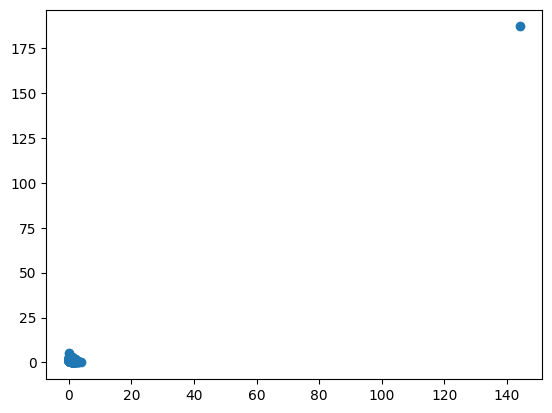

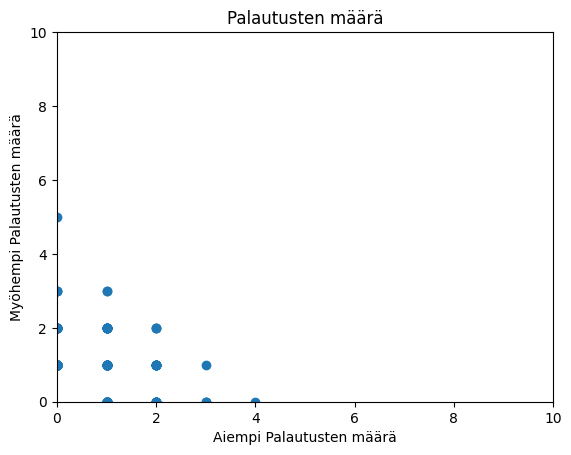

187.0 0.0
144.0 0.0


In [7]:
import matplotlib.pyplot as plt
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
neljannes = ((end-start))/4
early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Kuvaus"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Kuvaus"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity)
    lateravgs = np.append(lateravgs, lateractivity)
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautusten määrä")
plt.xlim(0, 10)
plt.xlabel("Aiempi Palautusten määrä")
plt.ylim(0, 10)
plt.ylabel("Myöhempi Palautusten määrä")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())

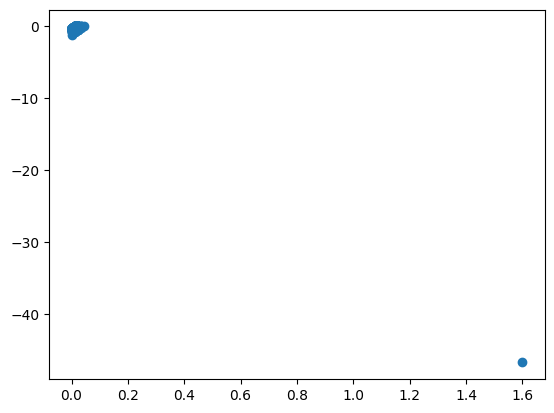

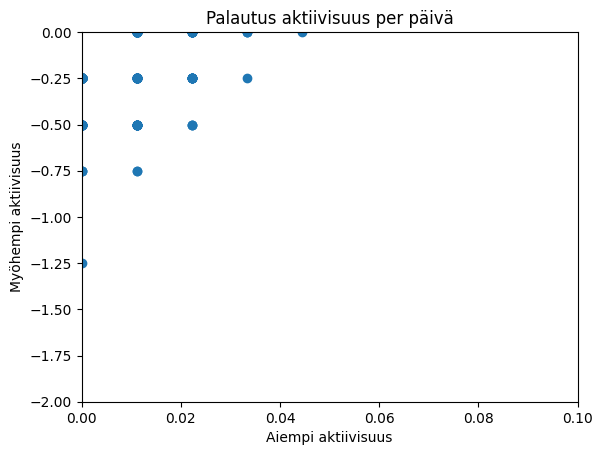

-0.0 -46.75
1.6 0.0


In [8]:
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]
early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = len(early[early["Kuvaus"].str.startswith(sr) == True].index)
    lateractivity = len(later[later["Kuvaus"].str.startswith(sr) == True].index)
    earlyavgs = np.append(earlyavgs, earlyactivity/neljannes.days)
    lateravgs = np.append(lateravgs, lateractivity/(((activity["Aika"].max()-activity["Aika"].min())).days-neljannes.days))
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Palautus aktiivisuus per päivä")
plt.xlim(0, 0.1)
plt.xlabel("Aiempi aktiivisuus")
plt.ylim(-2, 0)
plt.ylabel("Myöhempi aktiivisuus")
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())

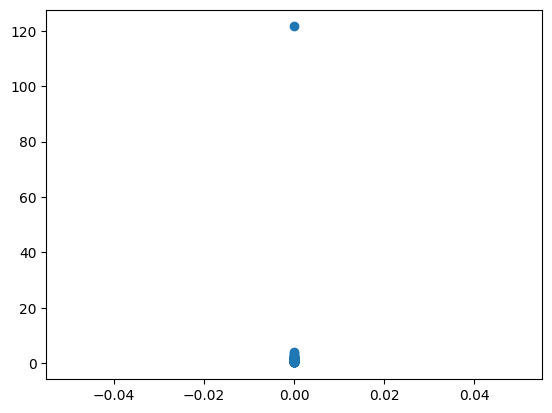

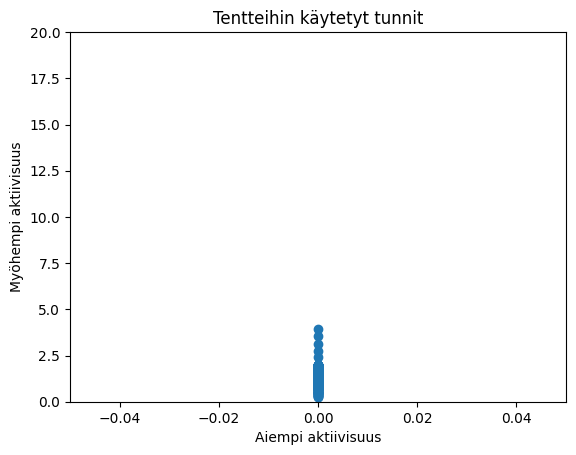

121.55222222222223 0.2611111111111111
0.0 0.0


In [9]:
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Tenttiin vastaaminen aloitettu"])]
neljannes = ((activity["Aika"].max()-activity["Aika"].min()))/4
early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]
earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)
for i in ids:
    sr = "The user with id '"+i
    earlyactivity = pd.concat([early[early["Kuvaus"].str.startswith(sr) == True]])
    lateractivity = pd.concat([later[later["Kuvaus"].str.startswith(sr) == True]])
    earlyactivity = earlyactivity.sort_values(by="Aika").to_numpy()
    lateractivity = lateractivity.sort_values(by="Aika").to_numpy()
#    if len(earlyactivity) > 0:
#        print(earlyactivity[0])
#    if len(lateractivity) > 0:
#        print(lateractivity[0])
    total_time = 0
    counter = 0
    start_time = None
    if len(earlyactivity) > 0:
        for l in earlyactivity:
            if l[3] == "Tenttiin vastaaminen aloitettu":#Tapahtuman nimi
                if counter == 0:
                    start_time = l[0]
                counter += 1
            else:
                counter -= 1
                if counter == 0:
                    total_time += (l[0]-start_time).total_seconds()/3600
                    start_time = None
    earlyavgs = np.append(earlyavgs, total_time)
    total_time = 0
    if len(lateractivity) > 0:
        for l in lateractivity:
            if l[3] == "Tenttiin vastaaminen aloitettu":#Tapahtuman nimi
                if counter == 0:
                    start_time = l[0]
                counter += 1
            else:
                counter -= 1
                if counter == 0:
                    total_time += (l[0]-start_time).total_seconds()/3600
                    start_time = None
    lateravgs = np.append(lateravgs, total_time)
plt.scatter(earlyavgs, lateravgs)
plt.show()
plt.title("Tentteihin käytetyt tunnit")
plt.xlabel("Aiempi aktiivisuus")
plt.ylabel("Myöhempi aktiivisuus")
plt.xlim(-0.05, 0.05)
plt.ylim(0, 20)
plt.scatter(earlyavgs, lateravgs)
plt.show()
print(lateravgs.max(), lateravgs.min())
print(earlyavgs.max(), earlyavgs.min())